In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
df = pd.read_csv("car data.csv")

In [17]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [5]:
df.shape

(301, 9)

In [6]:
df.isnull().sum()

,0
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


In [7]:
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [8]:
df.duplicated().sum()

np.int64(2)

In [9]:
df.drop_duplicates(inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

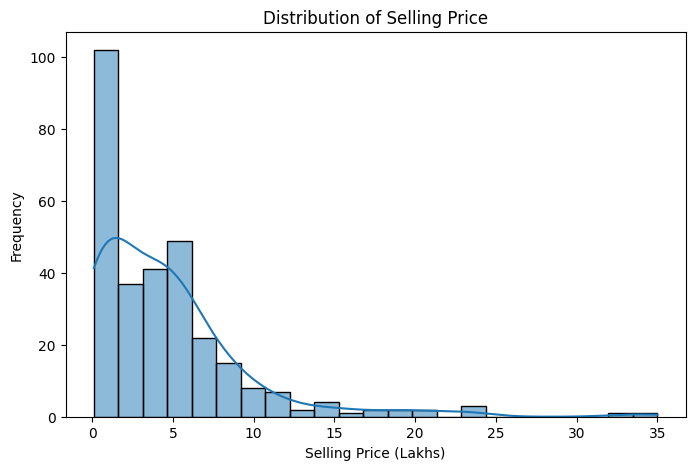

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['Selling_Price'], kde=True)
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price (Lakhs)')
plt.ylabel('Frequency')
plt.show()

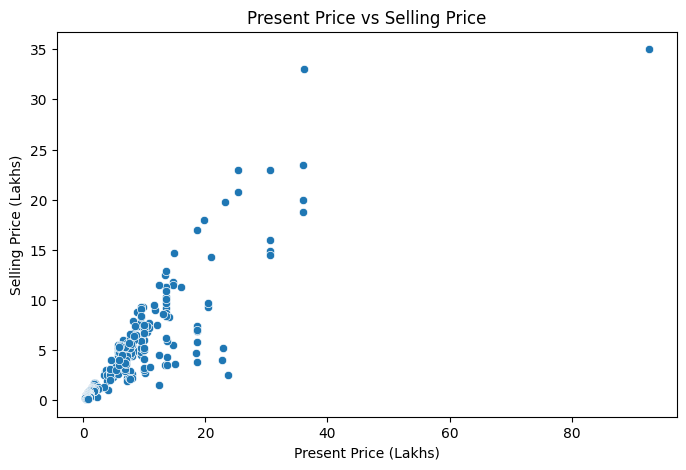

In [13]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Present_Price', y='Selling_Price', data=df)
plt.title('Present Price vs Selling Price')
plt.xlabel('Present Price (Lakhs)')
plt.ylabel('Selling Price (Lakhs)')
plt.show()

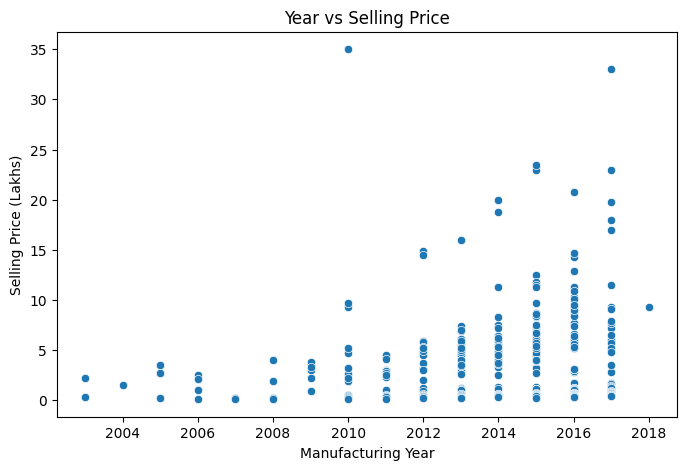

In [14]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Year', y='Selling_Price', data=df)
plt.title('Year vs Selling Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Selling Price (Lakhs)')
plt.show()

In [34]:
X = df[['Year', 'Present_Price', 'Driven_kms',
        'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']]
y = df['Selling_Price']

In [35]:
X = pd.get_dummies(X, drop_first=True)

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [37]:
y_pred = model.predict(X_test)

In [38]:
year = int(input("Enter car manufacturing year: "))
present_price = float(input("Enter present price (Lakhs): "))
driven_kms = int(input("Enter kilometers driven: "))
fuel_type = input("Enter fuel type (Petrol/Diesel/CNG): ")
selling_type = input("Enter seller type (Dealer/Individual): ")
transmission = input("Enter transmission (Manual/Automatic): ")
owner = int(input("Enter number of previous owners: "))

new_car = pd.DataFrame([{
    'Year': year,
    'Present_Price': present_price,
    'Driven_kms': driven_kms,
    'Owner': owner,
    'Fuel_Type': fuel_type,
    'Selling_type': selling_type,
    'Transmission': transmission
}])

new_car = pd.get_dummies(new_car)
new_car = new_car.reindex(columns=X_train.columns, fill_value=0)

prediction = model.predict(new_car)

print("\nPredicted Car Selling Price:", round(prediction[0], 2), "Lakhs")

Enter car manufacturing year: 2013
Enter present price (Lakhs): 1000000
Enter kilometers driven: 50000
Enter fuel type (Petrol/Diesel/CNG): CNG
Enter seller type (Dealer/Individual): Individual
Enter transmission (Manual/Automatic): Automatic
Enter number of previous owners: 3

Predicted Car Selling Price: 437121.76 Lakhs


In [41]:
y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 1.4725457508180229
MSE: 6.373125106262863
RMSE: 2.524504923002303
R2 Score: 0.7527233824219649
